# chquake: results figures

Figures only; all logic lives in `src/chquake`. Run `python scripts/download_data.py` first. Figures are also written to `outputs/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter

from chquake.exposure import load_exposure, value_by_canton
from chquake.vulnerability import assign_functions, load_vulnerability

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
RAW = ROOT / cfg["data"]["raw_dir"]
FIG = ROOT / cfg["run"]["output_dir"] / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Colours: one accent hue for the data of interest, grey for context, ink for all text.
ACCENT, CONTEXT = "#2a78d6", "#c3c2b7"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": CONTEXT, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

exposure = load_exposure(RAW / cfg["data"]["exposure"])
vuln = load_vulnerability(RAW / cfg["data"]["vulnerability"])
func = assign_functions(exposure["taxonomy"], RAW / cfg["data"]["vulnerability_mapping"], vuln)

## M1: exposure

ESRM20 residential exposure v1.0: total replacement value (structure + non-structural + contents, EUR at 2020 prices) per canton. A sanity check: value should roughly track population, so Zurich, Bern and Vaud lead and the small central cantons trail.

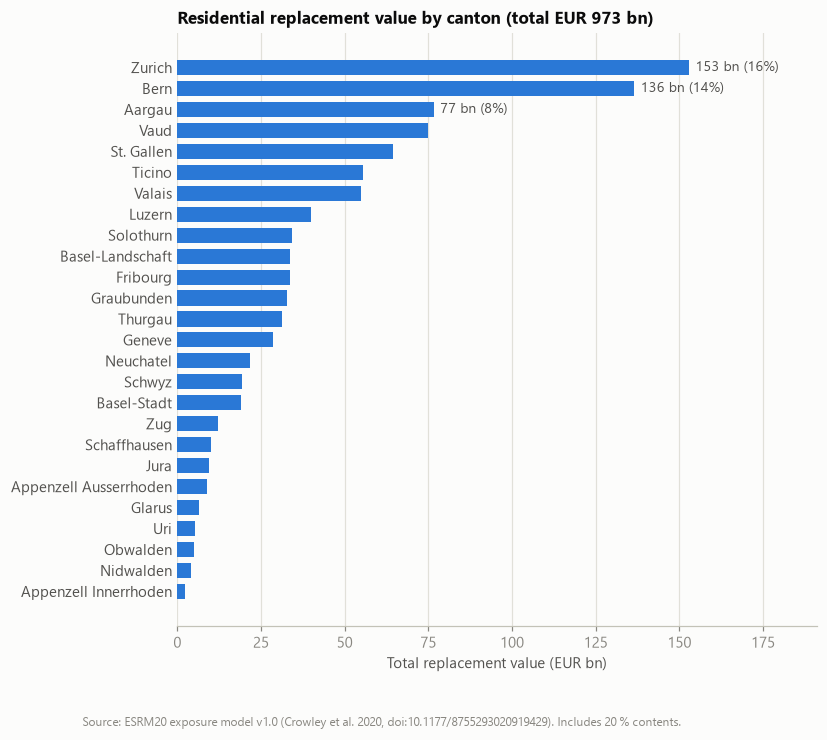

In [2]:
cant = value_by_canton(exposure).sort_values("value")
total = cant["value"].sum()

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(cant.index, cant["value"] / 1e9, height=0.72, color=ACCENT)
ax.xaxis.grid(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0, labelcolor=INK2)
for name in cant.index[-3:]:  # label only the three largest
    v = cant.loc[name, "value"]
    ax.text(v / 1e9 + 2, name, f"{v / 1e9:,.0f} bn ({v / total:.0%})", va="center",
            fontsize=9, color=INK2)
ax.set_xlim(0, cant["value"].max() / 1e9 * 1.25)
ax.set_xlabel("Total replacement value (EUR bn)")
ax.set_title(f"Residential replacement value by canton (total EUR {total / 1e9:,.0f} bn)")
fig.text(0.01, -0.02, "Source: ESRM20 exposure model v1.0 (Crowley et al. 2020, "
         "doi:10.1177/8755293020919429). Includes 20 % contents.", fontsize=8, color=MUTED)
fig.savefig(FIG / "m1_value_by_canton.png")
plt.show()

## M1: vulnerability

One panel per intensity measure, because a loss ratio at 0.3 g of PGA is not comparable to one at 0.3 g of SA(1.0). Grey: every ESRM20 function used by a Swiss residential class. Blue: the class carrying the most replacement value in that panel, with a ±1 standard-deviation band from the published CoV (the secondary uncertainty).

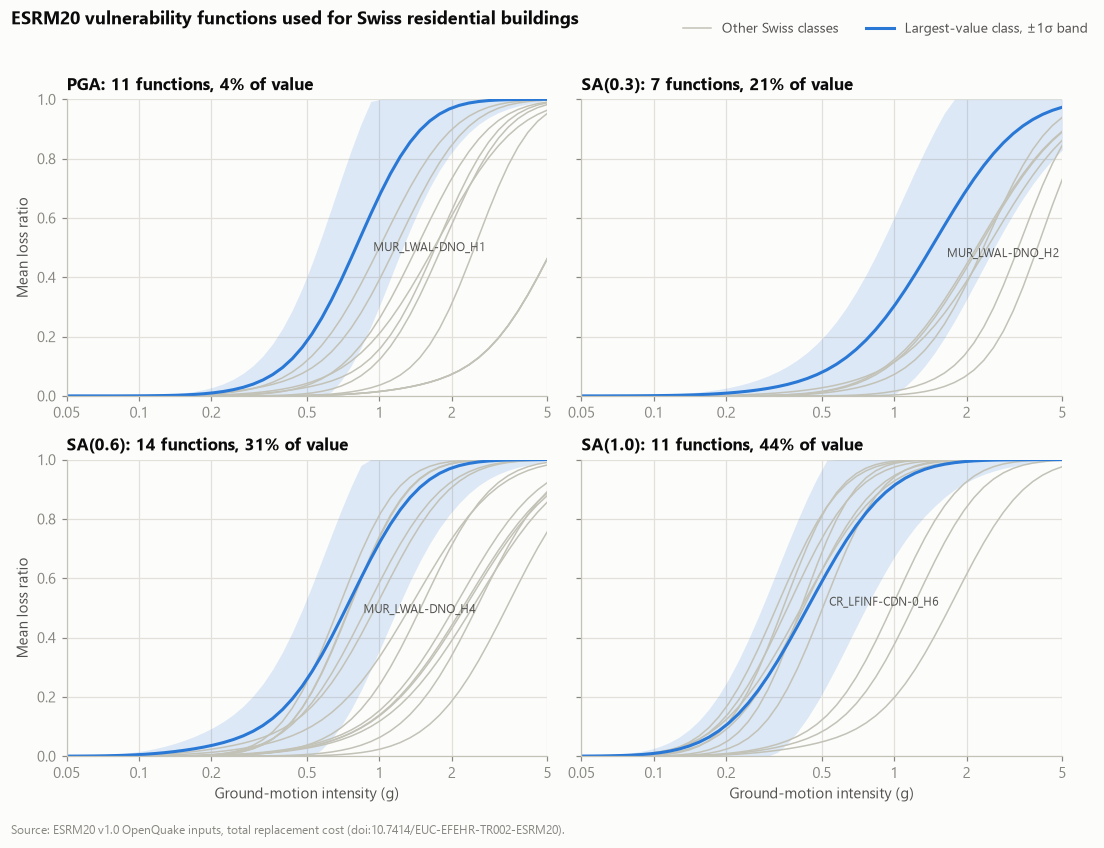

In [3]:
value_by_func = exposure.groupby(func)["value"].sum()
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), sharey=True)
for ax, imt in zip(axes.flat, ["PGA", "SA(0.3)", "SA(0.6)", "SA(1.0)"], strict=True):
    used = [f for f in value_by_func.index if vuln.imt[f] == imt]
    for f in used:
        ax.plot(vuln.iml, vuln.mean[f], color=CONTEXT, lw=1)
    top = max(used, key=value_by_func.get)
    m = vuln.mean[top]
    s = vuln.cov[top] * m
    ax.fill_between(vuln.iml, np.clip(m - s, 0, 1), np.clip(m + s, 0, 1),
                    color=ACCENT, alpha=0.15, lw=0)
    ax.plot(vuln.iml, m, color=ACCENT, lw=2)
    i = int(np.argmax(m >= 0.5)) if m.max() >= 0.5 else len(m) - 1
    ax.annotate(vuln.ids[top], (vuln.iml[i], m[i]), xytext=(8, -10),
                textcoords="offset points", fontsize=8, color=INK2)
    share = value_by_func[used].sum() / value_by_func.sum()
    ax.set_title(f"{imt}: {len(used)} functions, {share:.0%} of value")
    ax.set_xscale("log")
    ax.set_xlim(0.05, 5)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_locator(FixedLocator([0.05, 0.1, 0.2, 0.5, 1, 2, 5]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(FixedLocator([]))
    ax.grid(True)
for ax in axes[1]:
    ax.set_xlabel("Ground-motion intensity (g)")
for ax in axes[:, 0]:
    ax.set_ylabel("Mean loss ratio")
handles = [Line2D([], [], color=CONTEXT, lw=1, label="Other Swiss classes"),
           Line2D([], [], color=ACCENT, lw=2, label="Largest-value class, ±1σ band")]
fig.legend(handles=handles, loc="upper right", frameon=False, ncol=2, fontsize=9,
           labelcolor=INK2, bbox_to_anchor=(1.0, 1.02))
fig.suptitle("ESRM20 vulnerability functions used for Swiss residential buildings",
             x=0.01, ha="left", fontsize=12, fontweight="bold", y=1.02)
fig.tight_layout()
fig.text(0.01, -0.02, "Source: ESRM20 v1.0 OpenQuake inputs, total replacement cost "
         "(doi:10.7414/EUC-EFEHR-TR002-ESRM20).", fontsize=8, color=MUTED)
fig.savefig(FIG / "m1_vulnerability_curves.png")
plt.show()